<a href="https://colab.research.google.com/github/memphidelity/final/blob/main/p.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import os
import pandas as pd
import numpy as np
from scipy import stats

pred_dir = '/content/drive/MyDrive/A/thesis/final/predictions'
baseline_file = os.path.join(pred_dir, 'vggish_test_predictions.csv')
# Lowercase model suffixes matching the actual file names
models = ['ast', 'bat', 'eat', 'sslam']
metrics = [
    'prob_engine_presence',
    'prob_machinery-impact_presence',
    'prob_non-machinery-impact_presence',
    'prob_powered-saw_presence',
    'prob_alert-signal_presence',
    'prob_music_presence',
    'prob_human-voice_presence',
    'prob_dog_presence'
]

df_vgg = pd.read_csv(baseline_file)
results = []

for model in models:
    model_file = os.path.join(pred_dir, f'{model}_test_predictions.csv')
    if not os.path.exists(model_file):
        print(f'Warning: {model_file} not found.')
        continue
    df_model = pd.read_csv(model_file)
    merged = pd.merge(df_vgg, df_model, on='audio_filename', suffixes=('_vgg', f'_{model}'))

    for metric in metrics:
        col_vgg = f'{metric}_vgg'
        col_model = f'{metric}_{model}'

        t_stat, p_val_t = stats.ttest_rel(merged[col_model], merged[col_vgg])
        w_stat, p_val_w = stats.wilcoxon(merged[col_model], merged[col_vgg])

        mean_vgg = merged[col_vgg].mean()
        mean_model = merged[col_model].mean()
        diff = mean_model - mean_vgg

        results.append({
            'Model': model.upper(),
            'Category': metric.replace('prob_', '').replace('_presence', ''),
            'Mean_VGG': mean_vgg,
            'Mean_Model': mean_model,
            'Mean_Diff': diff,
            't_stat': t_stat,
            'p_value_t_test': p_val_t,
            'p_value_wilcoxon': p_val_w
        })

df_results = pd.DataFrame(results)
df_results['Significant_t_test'] = df_results['p_value_t_test'] < 0.05
df_results['Significant_wilcoxon'] = df_results['p_value_wilcoxon'] < 0.05

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print('=== Statistical Comparison Against VGGish Baseline ===')
display(df_results)

print('\n=== Best Performing Model per Category ===')
for cat in df_results['Category'].unique():
    cat_data = df_results[df_results['Category'] == cat]
    best_row = cat_data.loc[cat_data['Mean_Model'].idxmax()]
    print(f"Category: {cat:<25} | Best Model: {best_row['Model']:<6} (Mean: {best_row['Mean_Model']:.4f} vs VGG: {best_row['Mean_VGG']:.4f}, p-val Wilcoxon: {best_row['p_value_wilcoxon']:.2e})")

=== Statistical Comparison Against VGGish Baseline ===


,Model,Category,Mean_VGG,Mean_Model,Mean_Diff,t_stat,p_value_t_test,p_value_wilcoxon,Significant_t_test,Significant_wilcoxon
0,AST,engine,0.353123,0.420090,0.066968,6.637323,6.646865e-11,2.602287e-09,True,True
1,AST,machinery-impact,0.040721,0.070607,0.029885,9.497407,3.828412e-20,9.847402e-39,True,True
2,AST,non-machinery-impact,0.080444,0.052597,-0.027847,-6.458977,2.039879e-10,5.178956e-19,True,True
3,AST,powered-saw,0.009780,0.017364,0.007584,4.117688,4.310375e-05,3.865285e-23,True,True
4,AST,alert-signal,0.188337,0.161770,-0.026566,-2.867313,4.271178e-03,2.668044e-01,True,False
5,AST,music,0.067623,0.061099,-0.006524,-1.436114,1.514417e-01,3.745084e-01,False,False
6,AST,human-voice,0.440631,0.477105,0.036474,4.004986,6.903779e-05,1.781980e-02,True,True
7,AST,dog,0.028198,0.022691,-0.005507,-1.218603,2.234283e-01,9.014434e-37,False,True
8,BAT,engine,0.353123,0.404976,0.051853,6.021130,2.868695e-09,3.752017e-14,True,True
9,BAT,machinery-impact,0.040721,0.057633,0.016912,6.862223,1.558761e-11,2.889715e-32,True,True



=== Best Performing Model per Category ===
Category: engine                    | Best Model: EAT    (Mean: 0.4224 vs VGG: 0.3531, p-val Wilcoxon: 6.47e-17)
Category: machinery-impact          | Best Model: SSLAM  (Mean: 0.1193 vs VGG: 0.0407, p-val Wilcoxon: 1.17e-77)
Category: non-machinery-impact      | Best Model: SSLAM  (Mean: 0.0754 vs VGG: 0.0804, p-val Wilcoxon: 6.22e-01)
Category: powered-saw               | Best Model: EAT    (Mean: 0.0247 vs VGG: 0.0098, p-val Wilcoxon: 1.56e-59)
Category: alert-signal              | Best Model: SSLAM  (Mean: 0.2126 vs VGG: 0.1883, p-val Wilcoxon: 1.11e-28)
Category: music                     | Best Model: SSLAM  (Mean: 0.0843 vs VGG: 0.0676, p-val Wilcoxon: 5.88e-04)
Category: human-voice               | Best Model: AST    (Mean: 0.4771 vs VGG: 0.4406, p-val Wilcoxon: 1.78e-02)
Category: dog                       | Best Model: SSLAM  (Mean: 0.0356 vs VGG: 0.0282, p-val Wilcoxon: 3.37e-11)


In [10]:
import pandas as pd
from IPython.display import display

print("=== Summary of Significant Improvements ===")
print("(Criteria: Wilcoxon p-value < 0.05 AND Mean_Model > Mean_VGG)\n")

# Filter for significant positive improvements
improved_df = df_results[(df_results['Significant_wilcoxon'] == True) & (df_results['Mean_Diff'] > 0)].copy()

# 1. Rank models across all categories
ranking_df = improved_df.groupby('Model').agg(
    Num_Significant_Improvements=('Category', 'count'),
    Avg_Mean_Improvement=('Mean_Diff', 'mean')
).reset_index()

# Sort by number of improvements (descending), then by average improvement
ranking_df = ranking_df.sort_values(by=['Num_Significant_Improvements', 'Avg_Mean_Improvement'], ascending=[False, False]).reset_index(drop=True)
ranking_df.index = ranking_df.index + 1
ranking_df.index.name = 'Rank'

print("--- Overall Model Ranking ---")
display(ranking_df)
print("\n")

# 2. Detailed improvements as a table
print("--- Detailed Significant Improvements by Model ---")
# Format for better readability
improved_df['Improvement'] = improved_df['Mean_Diff'].apply(lambda x: f"+{x:.4f}")
improved_df['P-Value (Wilcoxon)'] = improved_df['p_value_wilcoxon'].apply(lambda x: f"{x:.2e}")

detailed_table = improved_df[['Model', 'Category', 'Mean_VGG', 'Mean_Model', 'Improvement', 'P-Value (Wilcoxon)']]

display(detailed_table.sort_values(by=['Model', 'Category']).reset_index(drop=True))


=== Summary of Significant Improvements ===
(Criteria: Wilcoxon p-value < 0.05 AND Mean_Model > Mean_VGG)

--- Overall Model Ranking ---


,Model,Num_Significant_Improvements,Avg_Mean_Improvement
Rank,,,
1,SSLAM,6,0.030836
2,AST,4,0.035228
3,EAT,3,0.036031
4,BAT,3,0.025951




--- Detailed Significant Improvements by Model ---


,Model,Category,Mean_VGG,Mean_Model,Improvement,P-Value (Wilcoxon)
0,AST,engine,0.353123,0.420090,+0.0670,2.60e-09
1,AST,human-voice,0.440631,0.477105,+0.0365,1.78e-02
2,AST,machinery-impact,0.040721,0.070607,+0.0299,9.85e-39
3,AST,powered-saw,0.009780,0.017364,+0.0076,3.87e-23
4,BAT,engine,0.353123,0.404976,+0.0519,3.75e-14
5,BAT,machinery-impact,0.040721,0.057633,+0.0169,2.89e-32
6,BAT,powered-saw,0.009780,0.018868,+0.0091,1.58e-44
7,EAT,engine,0.353123,0.422387,+0.0693,6.47e-17
8,EAT,machinery-impact,0.040721,0.064680,+0.0240,2.58e-39
9,EAT,powered-saw,0.009780,0.024652,+0.0149,1.56e-59


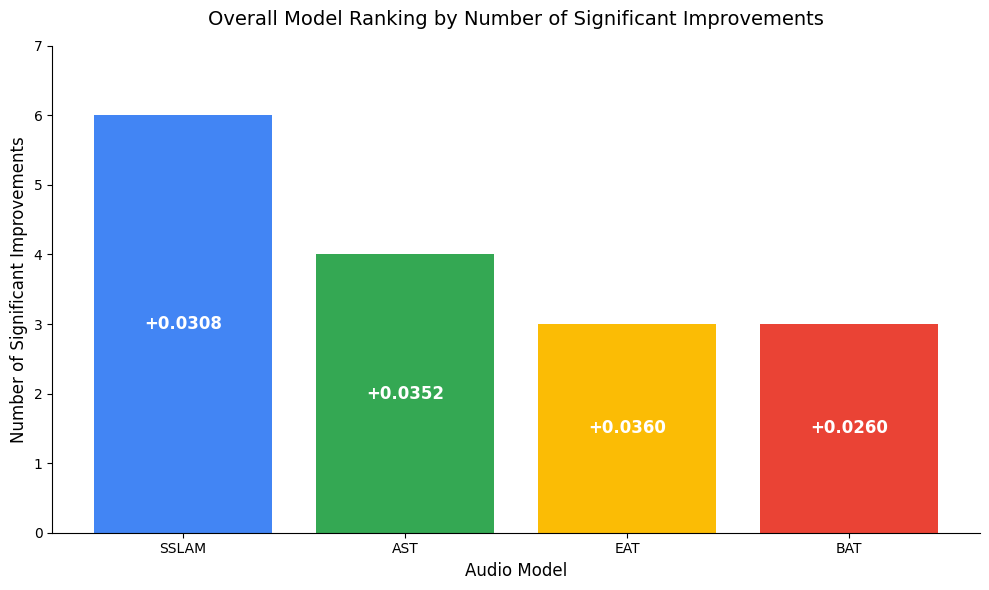

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Sort ranking dataframe by number of significant improvements
plot_df = ranking_df.sort_values(by=["Num_Significant_Improvements", "Avg_Mean_Improvement"], ascending=[False, False])

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot vertical bars
bars = ax.bar(
    plot_df["Model"],
    plot_df["Num_Significant_Improvements"],
    color=["#4285F4", "#34A853", "#FBBC05", "#EA4335"],
)

# Add the mean improvement value directly inside/on the bar
avg_means = plot_df["Avg_Mean_Improvement"].values
for bar, avg_mean in zip(bars, avg_means):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,  # Position horizontally in the middle of the bar
        height / 2,  # Vertically centered
        f"+{avg_mean:.4f}",  # Format value with 4 decimal places
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=12,
    )

# Chart styling
ax.set_xlabel("Audio Model", fontsize=12)
ax.set_ylabel("Number of Significant Improvements", fontsize=12)
ax.set_title(
    "Overall Model Ranking by Number of Significant Improvements",
    fontsize=14,
    pad=15,
)
ax.set_yticks(range(0, int(plot_df["Num_Significant_Improvements"].max()) + 2))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

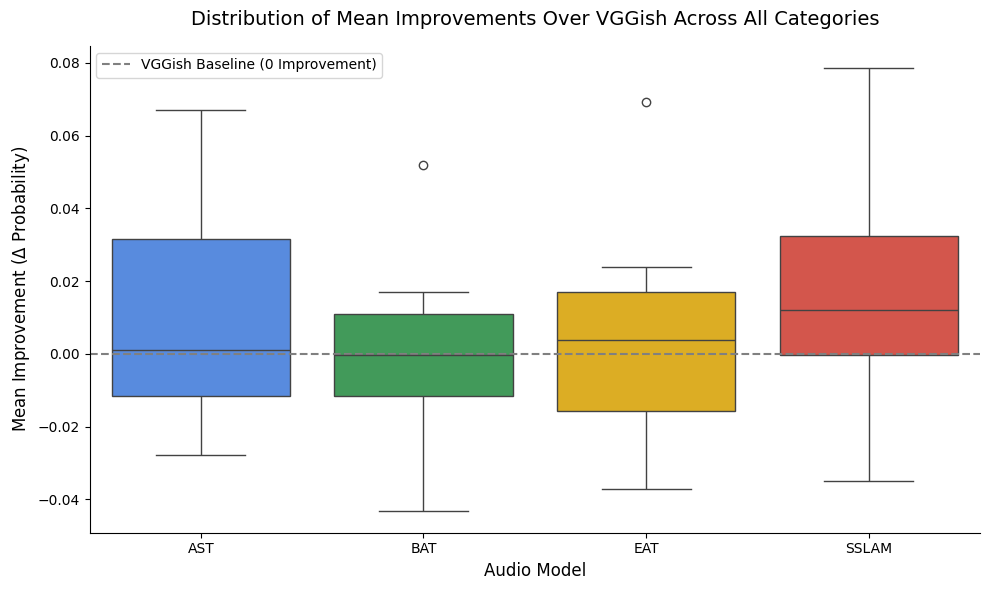

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# Boxplot of Mean_Diff for each model across all categories
# We use df_results to show the full distribution (8 categories per model)
sns.boxplot(
    data=df_results,
    x="Model",
    y="Mean_Diff",
    hue="Model",
    legend=False,
    palette=["#4285F4", "#34A853", "#FBBC05", "#EA4335"],
    ax=ax
)

# Add a dashed line at 0 to indicate the VGGish baseline performance
ax.axhline(0, color="gray", linestyle="--", label="VGGish Baseline (0 Improvement)")

# Chart styling
ax.set_title("Distribution of Mean Improvements Over VGGish Across All Categories", fontsize=14, pad=15)
ax.set_xlabel("Audio Model", fontsize=12)
ax.set_ylabel(r"Mean Improvement ($\Delta$ Probability)", fontsize=12)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
# Create a pivot table for mean improvements
summary_table = df_results.pivot(index='Category', columns='Model', values='Mean_Diff')

print("=== Mean Improvement (Model - VGGish) by Category ===")

# Find the maximum absolute value to center the colormap at 0
max_val = summary_table.abs().max().max()

# Display with a color gradient (green for positive improvement, red for negative)
display(summary_table.style.background_gradient(cmap='RdYlGn', vmin=-max_val, vmax=max_val).format("{:.4f}"))


=== Mean Improvement (Model - VGGish) by Category ===


Model,AST,BAT,EAT,SSLAM
Category,,,,
alert-signal,-0.0266,-0.0431,-0.0319,0.0243
dog,-0.0055,-0.0028,-0.0010,0.0074
engine,0.0670,0.0519,0.0693,0.0566
human-voice,0.0365,0.0025,0.0085,-0.0348
machinery-impact,0.0299,0.0169,0.0240,0.0786
music,-0.0065,-0.0030,-0.0103,0.0167
non-machinery-impact,-0.0278,-0.0370,-0.0372,-0.0051
powered-saw,0.0076,0.0091,0.0149,0.0014


### 1. Improvements by Category (Boxplot)
Let's visualize how the models perform on a per-category basis.

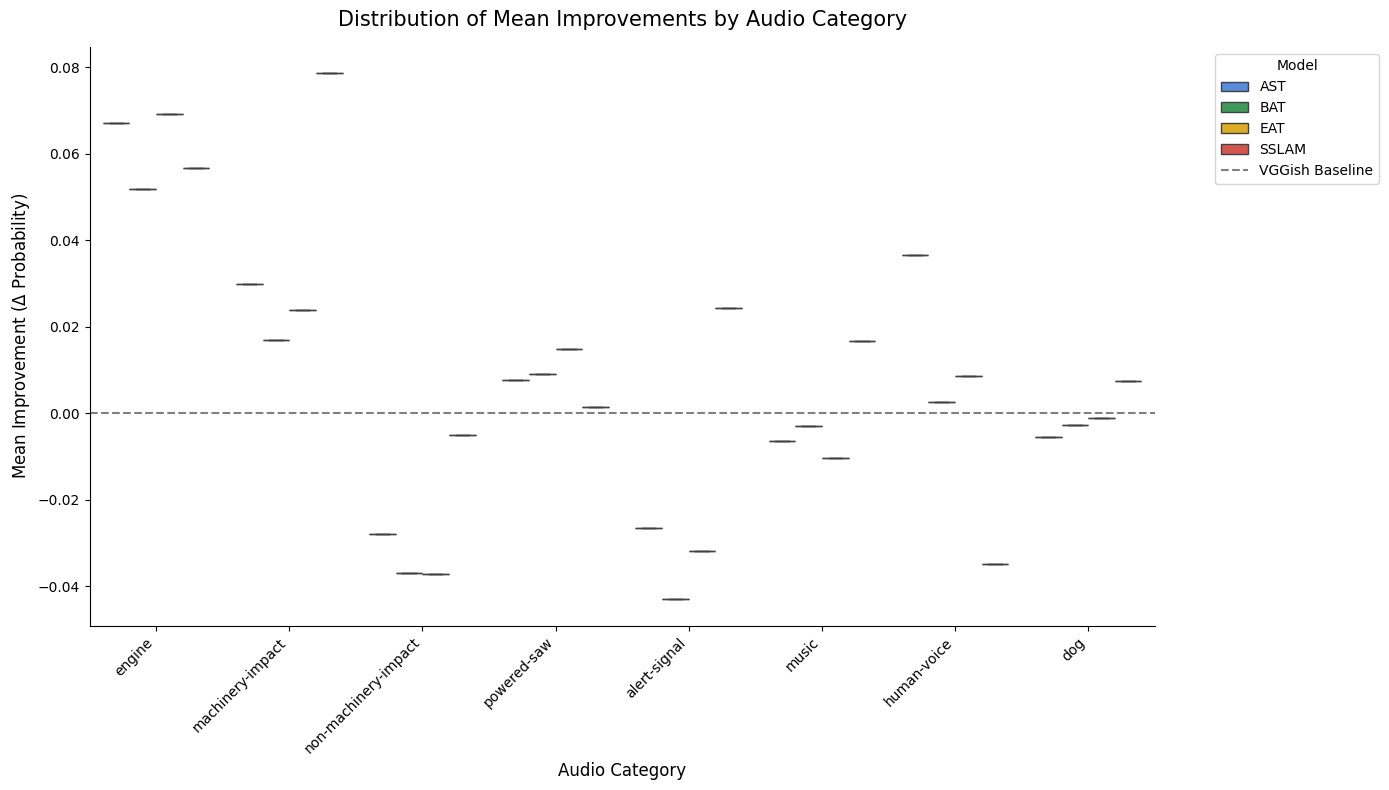

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 8))

# Grouped boxplot by Category
sns.boxplot(
    data=df_results,
    x="Category",
    y="Mean_Diff",
    hue="Model",
    palette=["#4285F4", "#34A853", "#FBBC05", "#EA4335"],
    ax=ax
)

# Add baseline
ax.axhline(0, color="gray", linestyle="--", label="VGGish Baseline")

# Styling
ax.set_title("Distribution of Mean Improvements by Audio Category", fontsize=15, pad=15)
ax.set_xlabel("Audio Category", fontsize=12)
ax.set_ylabel(r"Mean Improvement ($\Delta$ Probability)", fontsize=12)
plt.xticks(rotation=45, ha='right')
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()

plt.tight_layout()
plt.show()


### 2. Heatmap of Mean Improvements
A heatmap provides a fantastic at-a-glance view of exactly where models over-perform or under-perform the baseline.

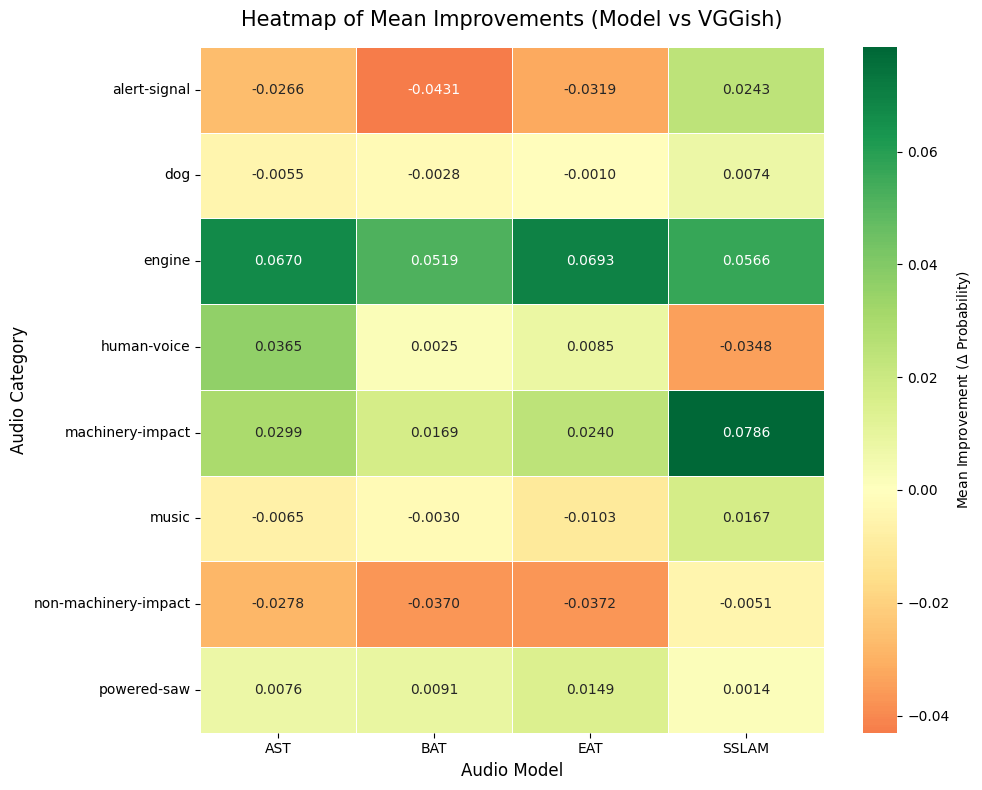

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))

# We reuse the summary_table pivot table created earlier
sns.heatmap(
    summary_table,
    annot=True,
    fmt=".4f",
    cmap="RdYlGn",
    center=0, # Seaborn heatmap supports center=0 directly
    cbar_kws={'label': r'Mean Improvement ($\Delta$ Probability)'},
    linewidths=.5,
    ax=ax
)

ax.set_title("Heatmap of Mean Improvements (Model vs VGGish)", fontsize=15, pad=15)
ax.set_ylabel("Audio Category", fontsize=12)
ax.set_xlabel("Audio Model", fontsize=12)

plt.tight_layout()
plt.show()
